# EDA 06 (tuning): tốc độ và khoảng trống thời gian

Tốc độ giữa hai điểm liên tiếp phân bố ra sao, có vùng trũng không, có phụ thuộc dt không; khoảng trống dài bao lâu, nhiều đến mức nào.

| Mục | Câu hỏi | Làm căn cứ cho |
|---|---|---|
| 1 | Tốc độ phân bố thế nào, có vùng trũng ở đâu, có phụ thuộc dt không? | Ngưỡng tốc độ outlier (A5) |
| 2 | Khoảng trống dài bao lâu, nhiều đến mức nào? | Ngưỡng tách segment (A7) |

**Cách chạy.** Cần chạy một lần `python src/preprocess/convert_raw.py` trước (chuyển dữ liệu thô sang `data/interim`). Sau đó Run All; notebook nạp dữ liệu từ `data/interim` và tính trong khoảng 1–2 phút. Muốn chạy thử nhanh thì đặt `USERS_LIMIT` ở cell đầu. Trong cùng một phiên, chỉ sửa cell phân tích thì chỉ cần chạy lại cell đó.

Code tính toán nằm trong `src/eda/` (`scan.py`, `config.py`). Mục đánh số riêng trong từng notebook (bảng mục và notebook ở README).

**Quy ước.** Timestamp gốc là UTC (theo User Guide). "Giờ địa phương" theo giả thuyết ở `src/eda/config.py`, kiểm chứng ở notebook 03 mục 2. Một "bước" là cặp hai điểm liên tiếp của cùng user sau khi sắp xếp theo thời gian và bỏ timestamp trùng.

> **Giai đoạn: TUNING (sau khi chia validation / test).** Chỉ đọc **nhóm validation** (`split.val_users()`). Không dùng nhóm test (D17, D19).
>
> Các số trong ô văn bản bên dưới là của lần chạy cũ (bản chia 06/11); cập nhật sau khi chạy lại.

In [7]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from eda.config import *          # dữ kiện từ tài liệu, mốc mô tả, bins (xem src/eda/config.py)
from eda.utils import pct, hist_quantile, qtable, fmt_s
from eda.scan import run
from eda import split

USERS_LIMIT = split.val_users()   # nhóm validation (D17); KHÔNG đặt None ở notebook tuning: sẽ đọc cả nhóm test (D17)

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100

R = run(topics=['speed'], users=USERS_LIMIT)
users, files, A = R.users, R.files, R.A
modes = R.modes
print(f"{len(users)} user, {len(files):,} file")

[20/115] đã đọc tới user 033 (3 giây)
[40/115] đã đọc tới user 063 (6 giây)
[60/115] đã đọc tới user 102 (7 giây)
[80/115] đã đọc tới user 132 (10 giây)
[100/115] đã đọc tới user 163 (14 giây)
[115/115] đã đọc tới user 180 (16 giây)
115 user, 12,376 file


## 1. Tốc độ giữa hai điểm liên tiếp

**Câu hỏi:** tốc độ phân bố thế nào, và có chỗ nào phân phối bị gãy giữa di chuyển bình thường và giá trị bất thường không?

Tốc độ chỉ phản ánh di chuyển khi hai điểm đủ gần nhau về thời gian. Notebook không chọn trước dt tối đa: số liệu được lưu dạng histogram hai chiều dt × tốc độ, nên có thể xem phân phối tốc độ ở nhiều mức dt (`DT_CUTS_S`).

**Cách đọc:** nếu các đường của các mức dt gần trùng nhau ở vùng tốc độ cao, vùng đó không phụ thuộc lựa chọn dt. Chỗ phân phối bị gãy (vùng trũng) là nơi ít bước sát ngưỡng nhất nếu sau này đặt ngưỡng lọc. Phân vị và đường phân phối chỉ tính các bước có tốc độ > 0 (thang log không chứa 0), nên khác với phân vị tính trên mọi bước; bảng đếm theo mốc tốc độ ở cell sau thì đếm chính xác trên mọi bước. Các vạch xám là tốc độ tham chiếu (đi bộ, cao tốc, máy bay), không phải ngưỡng.


,10 giây,1 phút,5 phút,30 phút,2 giờ,không giới hạn
"tốc độ (km/h), dt ≤",,,,,,
p50,15.0,15.0,15.0,15.0,15.0,15.0
p90,66.8,66.8,66.8,66.8,66.8,66.8
p95,94.4,94.4,94.4,94.4,94.4,94.4
p99,133.4,149.6,149.6,149.6,149.6,149.6
p99.9,211.3,237.1,237.1,237.1,237.1,237.1


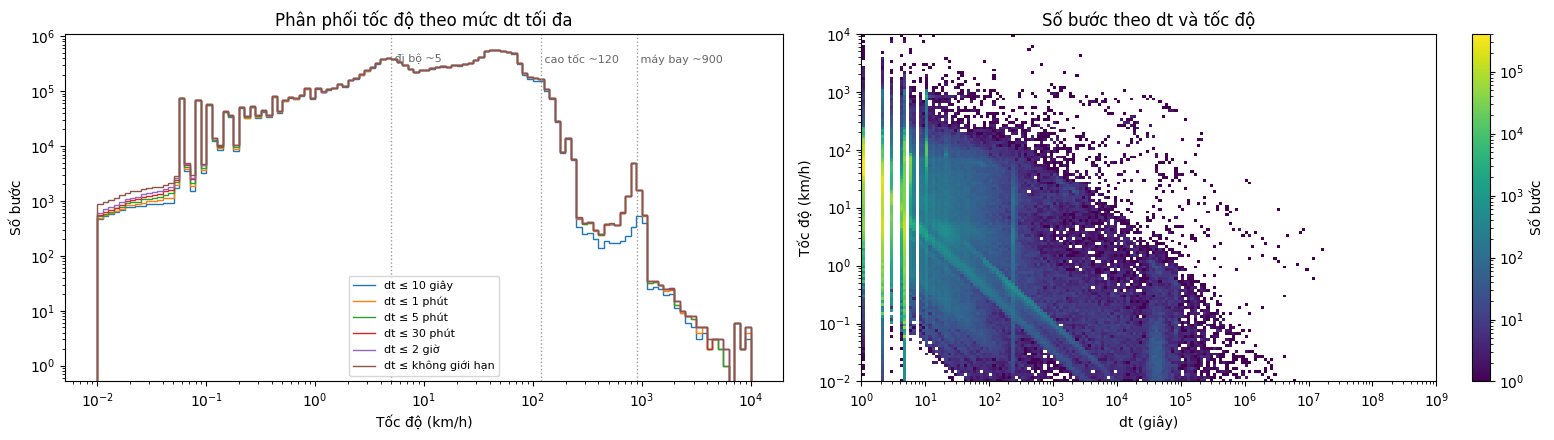

In [8]:
H2 = A["dt_sp_hist"]                       # [ô dt, ô tốc độ]
DT_UPPER = DT_BINS[1:]


def speed_hist_upto(cut_s):
    """Histogram tốc độ của các bước có dt ≤ cut_s (xấp xỉ theo biên trên của ô dt)."""
    return H2[DT_UPPER <= cut_s * 1.0001].sum(axis=0)


qt = pd.DataFrame({fmt_s(c): [hist_quantile(speed_hist_upto(c), SPEED_BINS, q) for q in QUANTILES]
                   for c in DT_CUTS_S}, index=[f"p{q * 100:g}" for q in QUANTILES])
qt.index.name = "tốc độ (km/h), dt ≤"
display(qt.round(1))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
ax = axes[0]
for c in DT_CUTS_S:
    ax.stairs(speed_hist_upto(c), SPEED_BINS, label=f"dt ≤ {fmt_s(c)}")
ax.set_xscale("log"); ax.set_yscale("log")
for v_, lab in ((5, "đi bộ ~5"), (120, "cao tốc ~120"), (900, "máy bay ~900")):
    ax.axvline(v_, color="#999", ls=":", lw=1)
    ax.text(v_, ax.get_ylim()[1] * 0.3, f" {lab}", color="#666", fontsize=8)
ax.set_xlabel("Tốc độ (km/h)"); ax.set_ylabel("Số bước")
ax.set_title("Phân phối tốc độ theo mức dt tối đa")
ax.legend(fontsize=8)

ax = axes[1]
im = ax.pcolormesh(DT_BINS, SPEED_BINS, np.ma.masked_equal(H2, 0).T, norm=LogNorm(), cmap="viridis")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("dt (giây)"); ax.set_ylabel("Tốc độ (km/h)")
ax.set_title("Số bước theo dt và tốc độ")
plt.colorbar(im, ax=ax, label="Số bước")
plt.tight_layout()
plt.show()


In [9]:
cm = pd.DataFrame(A["cut_mark"].T, index=pd.Index(SPEED_MARKS, name="tốc độ > (km/h)"),
                  columns=[f"dt ≤ {fmt_s(c)}" for c in DT_CUTS_S])
print("Số bước vượt từng mốc tốc độ (đếm chính xác):")
display(cm)
print("Tỷ lệ % trên số bước có dt ≤ mức tương ứng:")
(cm / A["n_le_cut"] * 100).round(3)


Số bước vượt từng mốc tốc độ (đếm chính xác):


,dt ≤ 10 giây,dt ≤ 1 phút,dt ≤ 5 phút,dt ≤ 30 phút,dt ≤ 2 giờ,dt ≤ không giới hạn
tốc độ > (km/h),,,,,,
50,2847832,2856492,2858546,2858968,2859038,2859154
100,584649,587084,587543,587740,587789,587876
150,117533,118540,118769,118892,118925,119001
200,31376,31953,32109,32195,32221,32282
250,12203,12602,12690,12755,12780,12836
300,11567,11902,11970,12019,12044,12088
350,11071,11366,11425,11462,11487,11521
400,10767,11035,11088,11122,11146,11172
500,10212,10445,10490,10517,10540,10557


Tỷ lệ % trên số bước có dt ≤ mức tương ứng:


,dt ≤ 10 giây,dt ≤ 1 phút,dt ≤ 5 phút,dt ≤ 30 phút,dt ≤ 2 giờ,dt ≤ không giới hạn
tốc độ > (km/h),,,,,,
50,20.262,20.139,20.083,20.061,20.054,20.038
100,4.160,4.139,4.128,4.124,4.123,4.120
150,0.836,0.836,0.834,0.834,0.834,0.834
200,0.223,0.225,0.226,0.226,0.226,0.226
250,0.087,0.089,0.089,0.090,0.090,0.090
300,0.082,0.084,0.084,0.084,0.084,0.085
350,0.079,0.080,0.080,0.080,0.081,0.081
400,0.077,0.078,0.078,0.078,0.078,0.078
500,0.073,0.074,0.074,0.074,0.074,0.074


User có nhiều bước trên 1.000 km/h và 2.000 km/h (nhanh hơn máy bay thương mại). Đây là nơi nên xem bản đồ để hiểu kiểu lỗi.


In [10]:
users.nlargest(10, "n_speed_gt_1000")[["user", "n_steps", "n_speed_gt_1000", "n_speed_gt_2000"]]


,user,n_steps,n_speed_gt_1000,n_speed_gt_2000
38,062,330248,665,658
99,163,969083,210,1
75,128,1208308,174,11
50,082,172542,162,2
51,083,35051,58,4
92,153,2156963,18,3
1,002,248213,13,4
26,042,239371,11,2
10,017,1026175,10,5
24,039,267736,10,9


## 2. Khoảng trống thời gian

**Câu hỏi:** bước có dt lớn (tắt máy, mất tín hiệu, giữa hai chuyến đi) dài bao lâu và nhiều đến mức nào? Số khoảng trống thay đổi thế nào qua các mốc độ dài?


In [11]:
tbl = pd.DataFrame({"mốc_phút": GAP_MARKS_MIN, "số_bước_dài_hơn": A["gap_cnt"]})
tbl["tỷ_lệ_%_số_bước"] = tbl["số_bước_dài_hơn"] / A["n_steps"] * 100
tbl["giảm_so_với_mốc_trước"] = (-tbl["số_bước_dài_hơn"].diff()).fillna(0).astype(int)
display(tbl.set_index("mốc_phút").round(3))

per_day = pd.DataFrame({f"> {m} phút": users[f"n_gap_gt_{m}min"] / users["n_days"].clip(lower=1)
                        for m in GAP_MARKS_MIN})
print("Số khoảng trống mỗi ngày có dữ liệu, phân phối theo user:")
per_day.describe(percentiles=[0.25, 0.5, 0.75]).round(2).T


,số_bước_dài_hơn,tỷ_lệ_%_số_bước,giảm_so_với_mốc_trước
mốc_phút,,,
5,35445,0.248,0
10,25750,0.180,9695
30,17934,0.126,7816
60,14895,0.104,3039
180,11311,0.079,3584
360,9627,0.067,1684
720,5746,0.040,3881
1440,1934,0.014,3812


Số khoảng trống mỗi ngày có dữ liệu, phân phối theo user:


,count,mean,std,min,25%,50%,75%,max
> 5 phút,115.0,4.55,2.26,0.67,3.08,4.00,6.08,13.54
> 10 phút,115.0,3.14,1.41,0.67,2.33,2.96,3.68,9.04
> 30 phút,115.0,2.02,0.83,0.00,1.53,2.00,2.31,5.29
> 60 phút,115.0,1.66,0.61,0.00,1.36,1.62,2.01,3.74
> 180 phút,115.0,1.22,0.43,0.00,1.00,1.25,1.50,2.27
> 360 phút,115.0,1.02,0.36,0.00,0.83,1.05,1.25,1.63
> 720 phút,115.0,0.67,0.23,0.00,0.60,0.73,0.82,1.00
> 1440 phút,115.0,0.34,0.19,0.00,0.21,0.36,0.47,0.83


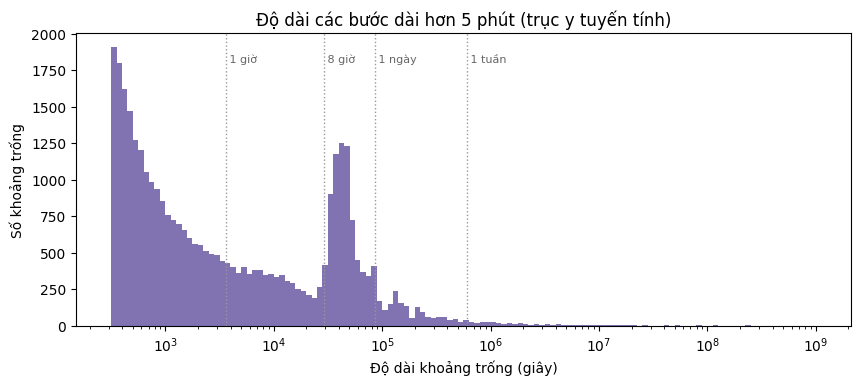

In [12]:
mask = DT_BINS[:-1] >= GAP_MARKS_MIN[0] * 60
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.stairs(A["dt_hist"][mask], DT_BINS[np.r_[mask, True]], fill=True, color="#8172b2")
ax.set_xscale("log")
for sec, label in ((3600, "1 giờ"), (8 * 3600, "8 giờ"), (86400, "1 ngày"), (7 * 86400, "1 tuần")):
    ax.axvline(sec, color="#999", ls=":", lw=1)
    ax.text(sec, ax.get_ylim()[1] * 0.9, f" {label}", fontsize=8, color="#666")
ax.set_xlabel("Độ dài khoảng trống (giây)")
ax.set_ylabel("Số khoảng trống")
ax.set_title(f"Độ dài các bước dài hơn {GAP_MARKS_MIN[0]} phút (trục y tuyến tính)")
plt.show()
